# Breast Cancer Prediction with NN model

This project uses a Neural network model to predict whether a breast tumor is **malignant** or **benign** based on measured characteristics from cancer images.

> This project is for educational machine-learning practice only. It must not be used for real medical diagnosis.

## Dataset

Each row represents one patient and includes:

- `id`: unique patient identifier
- `diagnosis`: target variable
  - `M`: malignant tumor
  - `B`: benign tumor
- Numeric features describing tumor characteristics, including:
  - `radius_mean`
  - `texture_mean`
  - `perimeter_mean`
  - `area_mean`
  - `smoothness_mean`
  - `compactness_mean`
  - `concavity_mean`
  - `concave points_mean`

## Goal

Train a nn model to predict the `diagnosis` column from the numerical tumor measurements.

```text
Input:  tumor measurements
Output: M (malignant) or B (benign)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import torch.nn as nn
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('Cancer_Data.csv')
df.sample(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
272,8910988,M,21.75,20.99,147.30,1491.0,0.09401,0.19610,0.21950,0.10880,...,28.18,195.90,2384.0,0.12720,0.4725,0.5807,0.18410,0.2833,0.08858,NaN
290,89143602,B,14.41,19.73,96.03,651.0,0.08757,0.16760,0.13620,0.06602,...,22.13,101.70,767.3,0.09983,0.2472,0.2220,0.10210,0.2272,0.08799,NaN
530,91858,B,11.75,17.56,75.89,422.9,0.10730,0.09713,0.05282,0.04440,...,27.98,88.52,552.3,0.13490,0.1854,0.1366,0.10100,0.2478,0.07757,NaN
77,8610637,M,18.05,16.15,120.20,1006.0,0.10650,0.21460,0.16840,0.10800,...,18.91,150.10,1610.0,0.14780,0.5634,0.3786,0.21020,0.3751,0.11080,NaN
84,8612080,B,12.00,15.65,76.95,443.3,0.09723,0.07165,0.04151,0.01863,...,24.90,87.78,567.9,0.13770,0.2003,0.2267,0.07632,0.3379,0.07924,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
df.drop(['id','Unnamed: 32'], axis=1, inplace=True)

In [7]:
df.sample(5)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.45040,0.24300,0.3613,0.08758
139,B,11.28,13.39,73.00,384.8,0.11640,0.11360,0.04635,0.04796,0.1771,...,11.92,15.77,76.53,434.0,0.1367,0.1822,0.08669,0.08611,0.2102,0.06784
247,B,12.89,14.11,84.95,512.2,0.08760,0.13460,0.13740,0.03980,0.1596,...,14.39,17.70,105.00,639.1,0.1254,0.5849,0.77270,0.15610,0.2639,0.11780
514,M,15.05,19.07,97.26,701.9,0.09215,0.08597,0.07486,0.04335,0.1561,...,17.58,28.06,113.80,967.0,0.1246,0.2101,0.28660,0.11200,0.2282,0.06954
264,M,17.19,22.07,111.60,928.3,0.09726,0.08995,0.09061,0.06527,0.1867,...,21.58,29.33,140.50,1436.0,0.1558,0.2567,0.38890,0.19840,0.3216,0.07570


In [10]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

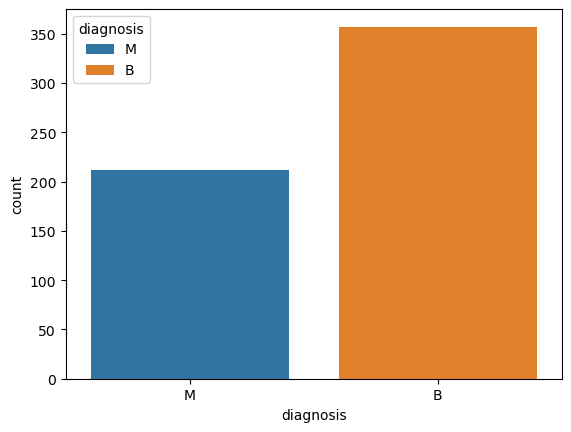

In [13]:
sns.countplot(df, x='diagnosis', hue='diagnosis', legend=True);

````
The labels are not so imbalanced and that is a good sign

In [16]:
df = pd.get_dummies(df, columns=['diagnosis'], dtype=int, drop_first=True)
df

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_M
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,1
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,1
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,1
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,1


In [23]:
len(df.columns)

31

In [17]:
X = df.drop('diagnosis_M', axis=1).values
y = df['diagnosis_M'].values

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [26]:
# now we define the class

class Model(nn.Module):
    def __init__(self, in_features=30, h1=128, h2=64, h3=32, out_features=2):
        super().__init__()
        self.fc1 = nn.Linear(30,128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64,32)
        self.out = nn.Linear(32,2)

    def forward(self,x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.out(x)
        return x

In [27]:
torch.manual_seed(42)
model = Model()

In [28]:
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=30, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (out): Linear(in_features=32, out_features=2, bias=True)
)>

In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [32]:
# now we train the model on train dataset

epochs = 100
losses = []

for epoch in range(epochs):
    y_pred = model.forward(X_train)
    loss = criterion(y_pred, y_train)
    losses.append(loss.item())

    if epoch%5 == 0:
        print(f'the epoch {epoch} has loss {loss}.')

    # Backpropogation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

the epoch 0 has loss 7.8290629386901855.
the epoch 5 has loss 0.620417594909668.
the epoch 10 has loss 0.44190898537635803.
the epoch 15 has loss 0.4115176498889923.
the epoch 20 has loss 0.39408349990844727.
the epoch 25 has loss 0.3498738408088684.
the epoch 30 has loss 0.3135276734828949.
the epoch 35 has loss 0.2925783395767212.
the epoch 40 has loss 0.27746155858039856.
the epoch 45 has loss 0.266607403755188.
the epoch 50 has loss 0.2545815408229828.
the epoch 55 has loss 0.24573566019535065.
the epoch 60 has loss 0.23479919135570526.
the epoch 65 has loss 0.22870557010173798.
the epoch 70 has loss 0.22330841422080994.
the epoch 75 has loss 0.2179705649614334.
the epoch 80 has loss 0.21386517584323883.
the epoch 85 has loss 0.21024712920188904.
the epoch 90 has loss 0.207044780254364.
the epoch 95 has loss 0.20410533249378204.


````
Let's visualize the losses

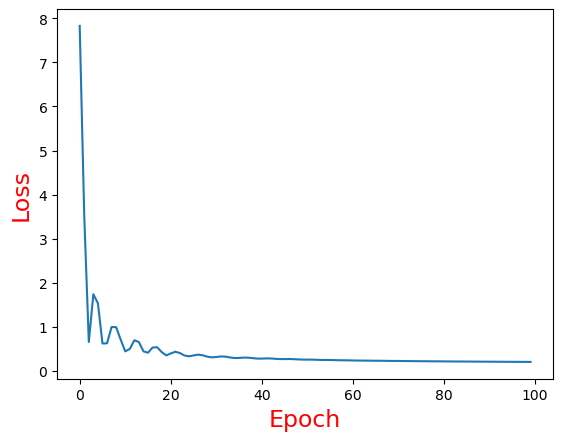

In [39]:
plt.plot(range(epochs), losses)
plt.xlabel('Epoch', c='r', fontsize=17)
plt.ylabel('Loss', c='r', fontsize=17);

### Now we apply fit the model on test dataset to evaluate the prediction

In [67]:
model.eval()
correct = 0
correct_m = 0
with torch.no_grad():
    for i, data in enumerate(X_test):
        y_eval = model.forward(data)
        loss = criterion(y_eval, y_test[i])
        predicted_value = y_eval.argmax().item()
        true_value = y_test[i]
        #print(f'{i+1}  {predicted_value}  {true_value}')

        if predicted_value == true_value:
            correct += 1
            if true_value == 1:
                correct_m += 1


total_class_1 = (y_test == 1).sum().item()




print(f'total correct predicted values are: {correct}')
print(f'________________________\n')

print(f'total correct_m predicted values are: {correct_m}')
print(f'the ratio correct_m predicted values are: {100 * (correct_m)/(total_class_1)}\n')

print(f'the ratio of predicted correct is: {round(100 * (correct) / len(y_test),2)}%')

total correct predicted values are: 109
________________________

total correct_m predicted values are: 40
the ratio correct_m predicted values are: 93.02325581395348

the ratio of predicted correct is: 95.61%
